# Experiment 07: 31 leaves against untuned and tuned

Card: [exp07_31_leaves.md](../../experiments/exp07_31_leaves.md)


In [1]:
import os
import sys
from time import perf_counter, strftime

import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, METERS, MLFLOW_URI
from ashrae.metrics import rmsle, rmsle_by_meter
from ashrae.tracking import log_run
from ashrae.tuning import make_folds, progress

SMOKE = os.environ.get("SMOKE") == "1"
LEARNING_RATE = 0.1
MODEL = "lgbm_building_31_leaves"
if SMOKE:
    EXPERIMENT = "ashrae-baseline-tuning-smoke"
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    LEAVES, TREES = 7, 30
    TUNED_SESSION = None  # the latest exp05 smoke session
    EXP06_SESSION = None  # no reproducibility check
    FIGURE = None
else:
    EXPERIMENT = "ashrae-baseline-tuning"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    LEAVES, TREES = 31, 1000  # exp06: same gap as untuned (about 0.14)
    TUNED_SESSION = "2026-10-11 17:34:12"  # exp05 tuned runs with 1,736 trees
    EXP06_SESSION = "2026-10-11 18:27:13"  # exp06 curves, to match at tree 1,000
    FIGURE = "../../figures/exp07_31_leaves.png"
SESSION = strftime("%Y-%m-%d %H:%M:%S")  # tag shared by this execution's runs
PARAMS = {"learning_rate": LEARNING_RATE, "num_leaves": LEAVES, "n_estimators": TREES}

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.MlflowClient()

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Training


In [2]:
folds = make_folds({f: FOLDS[f] for f in FOLD_NAMES}, N_TRAIN, N_VAL)
unclipped = {}  # LightGBM's own validation rmse at the last tree, to compare with exp06
for fold, d in folds.items():
    history = {}
    start = perf_counter()
    model = lgb.LGBMRegressor(**PARAMS, metric="rmse", random_state=0, verbose=-1).fit(
        d["X_train"],
        d["y_train"],
        eval_X=(d["X_val"],),
        eval_y=(d["y_val"],),
        eval_names=["all"],
        callbacks=[
            lgb.record_evaluation(history),
            progress(f"{MODEL} | {fold}", TREES),
        ],
    )
    train_seconds = perf_counter() - start
    unclipped[fold] = history["all"]["rmse"][-1]
    pred = np.clip(model.predict(d["X_val"]), 0, None)
    metrics = {
        **rmsle_by_meter(d["y_val"], pred, d["meter"]),
        "val_rmsle_clean": rmsle(d["y_val"][d["clean"]], pred[d["clean"]]),
        "train_rmsle": rmsle(d["y_train"], model.predict(d["X_train"])),
        "train_seconds": train_seconds,
    }
    log_run(
        EXPERIMENT,
        f"{MODEL} | {fold}",
        params={**PARAMS, "n_train": N_TRAIN, "n_val": N_VAL},
        metrics=metrics,
        tags={
            "session": SESSION,
            "stage": "31_leaves",
            "fold": fold,
            "model": MODEL,
            "notebook": "exp07_31_leaves",
        },
    )

fold data: 100%|██████████| 4/4 [00:04<00:00,  1.22s/fold]
lgbm_building_31_leaves | Jan–Mar: 100%|██████████| 1000/1000 [00:13<00:00, 76.52tree/s, best 1.4311 at 1000]            
lgbm_building_31_leaves | Apr–Jun: 100%|██████████| 1000/1000 [00:13<00:00, 76.76tree/s, best 1.2381 at 1000]            
lgbm_building_31_leaves | Jul–Sep: 100%|██████████| 1000/1000 [00:13<00:00, 76.73tree/s, best 1.0901 at 1000]            
lgbm_building_31_leaves | Oct–Dec: 100%|██████████| 1000/1000 [00:13<00:00, 76.38tree/s, best 1.1153 at 997]            


## Results


Oct–Dec: |difference| against exp06 at tree 1000: 0.00e+00
Jul–Sep: |difference| against exp06 at tree 1000: 0.00e+00
Apr–Jun: |difference| against exp06 at tree 1000: 0.00e+00
Jan–Mar: |difference| against exp06 at tree 1000: 0.00e+00


,val_rmsle,val_rmsle_clean,train_rmsle,train_seconds
fold average,,,,
untuned,1.217,0.959,0.815,9.923
31 leaves,1.218,0.962,0.825,13.069
tuned,1.181,0.911,0.599,58.985


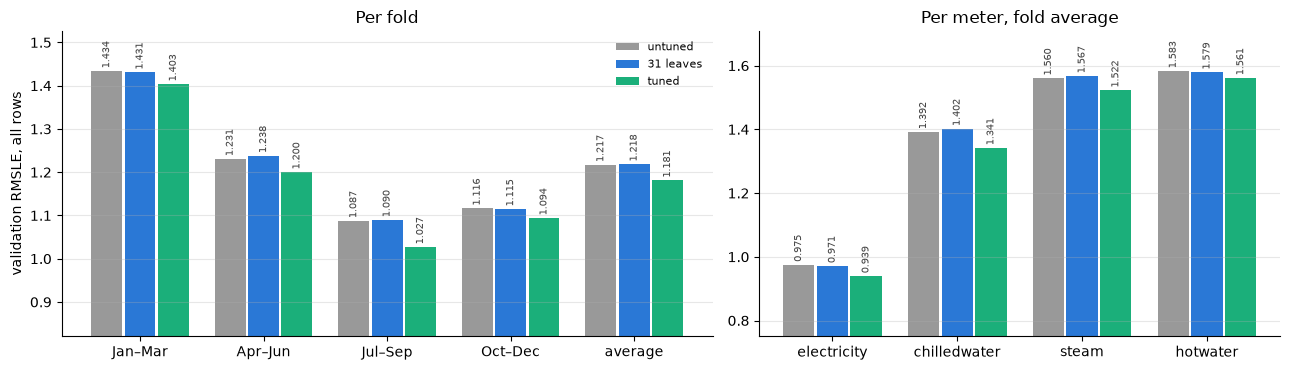

In [3]:
# Reproducibility: exp06 logged the same model's validation curve every 10 trees
if EXP06_SESSION:
    exp06 = mlflow.search_runs(
        experiment_names=[EXPERIMENT],
        filter_string=f"tags.stage = 'gap' and tags.session = '{EXP06_SESSION}' "
        f"and params.num_leaves = '{LEAVES}'",
    )
    for _, r in exp06.iterrows():
        step = {
            m.step: m.value
            for m in client.get_metric_history(r.run_id, "val_rmsle_curve_all")
        }
        print(
            f"{r['tags.fold']}: |difference| against exp06 at tree {TREES}: "
            f"{abs(step[TREES] - unclipped[r['tags.fold']]):.2e}"
        )

new_runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string=f"tags.stage = '31_leaves' and tags.session = '{SESSION}'",
)
tuned_runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT], filter_string="tags.stage = 'final'"
)
if TUNED_SESSION is None:
    TUNED_SESSION = tuned_runs["tags.session"].max()
tuned_runs = tuned_runs[tuned_runs["tags.session"] == TUNED_SESSION]
untuned_runs = mlflow.search_runs(
    experiment_names=["ashrae-baseline-building"],
    filter_string="tags.model = 'lgbm_building'",
)
untuned_runs = untuned_runs[
    untuned_runs["tags.session"] == untuned_runs["tags.session"].max()
]
untuned_runs = untuned_runs[untuned_runs["tags.fold"].isin(FOLD_NAMES)]
MODELS = ["untuned", f"{LEAVES} leaves", "tuned"]
final = pd.concat(
    [
        untuned_runs.assign(**{"tags.model": MODELS[0]}),
        new_runs.assign(**{"tags.model": MODELS[1]}),
        tuned_runs.assign(**{"tags.model": MODELS[2]}),
    ]
)

by_fold = final.pivot(
    index="tags.fold", columns="tags.model", values="metrics.val_rmsle"
).loc[FOLD_NAMES, MODELS]
by_fold.loc["average"] = by_fold.mean()
meter_cols = [f"metrics.val_rmsle_{name}" for name in METERS.values()]
by_meter = final.groupby("tags.model")[meter_cols].mean().loc[MODELS].T
by_meter.index = list(METERS.values())

COLORS = dict(
    zip(MODELS, ["#999999", "#eb6834", "#2a78d6"])
)  # untuned and tuned as in exp05
fig, axes = plt.subplots(
    1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [len(by_fold), len(by_meter)]}
)
for ax, scores, title in zip(
    axes, [by_fold, by_meter], ["Per fold", "Per meter, fold average"]
):
    x, width = np.arange(len(scores)), 0.27
    floor = 0.8 * scores.min().min()  # bars start here, so the differences are visible
    for i, name in enumerate(MODELS):
        bars = ax.bar(
            x + (i - 1) * width,
            scores[name] - floor,
            width - 0.02,
            bottom=floor,
            color=COLORS[name],
            label=name,
        )
        ax.bar_label(
            bars,
            labels=[f"{v:.3f}" for v in scores[name]],
            fontsize=7,
            color="#444",
            rotation=90,
            padding=2,
        )
    ax.set(xticks=x, xticklabels=scores.index, title=title)
    ax.margins(y=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("validation RMSLE, all rows")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in new_runs.run_id:
        client.log_artifact(run_id, FIGURE)

display(
    final.groupby("tags.model")[
        [
            "metrics.val_rmsle",
            "metrics.val_rmsle_clean",
            "metrics.train_rmsle",
            "metrics.train_seconds",
        ]
    ]
    .mean()
    .loc[MODELS]
    .rename(columns=lambda c: c.removeprefix("metrics."))
    .round(3)
    .rename_axis("fold average")
)